<a href="https://colab.research.google.com/github/Balkrishnakc17/Numerical-Methods/blob/main/FlightDelay.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Prompt:
I want to vibe code a multiple regression model using synthetic data for airline flight delays. Predict flight delay time using weather conditions, flight distance, departure time, airport traffic, airline performance, and day of the week. Generate synthetic data, build and evaluate the regression model, and create graphs. Also create an interactive prediction section using sliders or input boxes. I want to manually change the values of the variables and immediately see the new predicted flight delay in the output. Use simple Python code with ipywidgets that works in Google Colab and explain each step.



--- Step 1: Generating Synthetic Flight Delay Data ---
   Weather_Severity  Flight_Distance  Departure_Hour  Airport_Traffic  \
0          3.745401       636.885494        6.280936         3.690812   
1          9.507143      1671.512747        5.927491         4.186726   
2          7.319939      2631.542924       21.750110         2.001872   
3          5.986585      2223.452171        5.989109         3.499496   
4          1.560186      2439.027329        6.526793         3.286984   

   Airline_Delay_Factor  Day_of_Week  Delay_Minutes  
0              1.200397            3      87.228490  
1              1.363803            7     140.132464  
2              1.332113            3     101.016744  
3              0.907730            6     109.764186  
4              0.904475            4      65.776888  

--- Step 2: Training Multiple Linear Regression Model ---
Mean Squared Error (MSE): 44.17
R-squared (R2) Score: 0.91


/tmp/ipykernel_1012/2970785188.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=coefficients, y=features, palette='viridis')


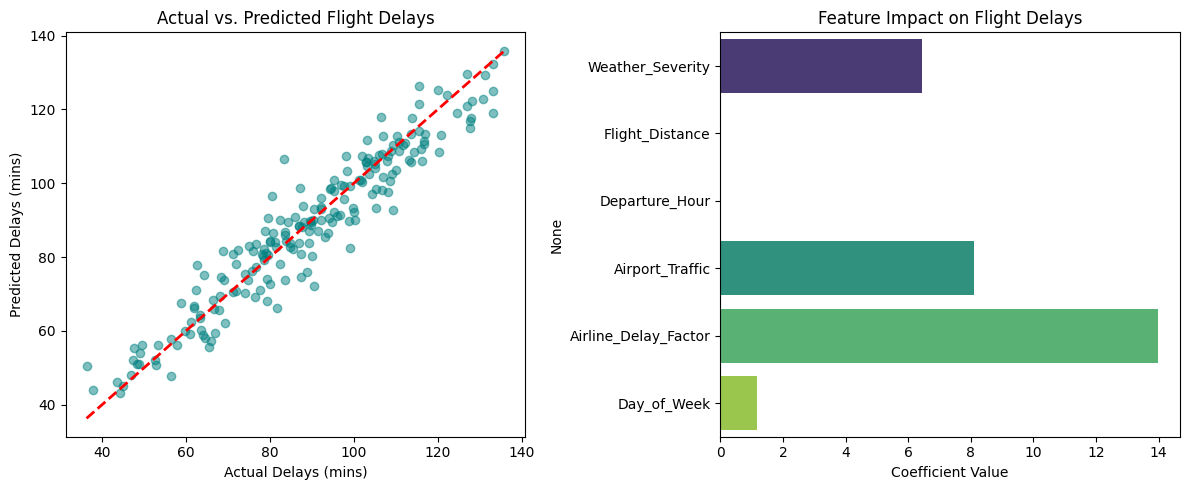


--- Step 4: Interactive Delay Predictor ---


Output()

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import ipywidgets as widgets
from IPython.display import display

# 1. Generate Synthetic Data
print("--- Step 1: Generating Synthetic Flight Delay Data ---")
np.random.seed(42)
n_samples = 1000

# Features
weather_severity = np.random.uniform(0, 10, n_samples)      # 0 (perfect) to 10 (stormy)
flight_distance = np.random.uniform(100, 3000, n_samples)     # in miles
departure_hour = np.random.uniform(0, 24, n_samples)         # hour of day
airport_traffic = np.random.uniform(1, 5, n_samples)         # 1 (low) to 5 (extreme congestion)
airline_delay_factor = np.random.uniform(0.8, 1.5, n_samples) # multiplier for airline performance
day_of_week = np.random.randint(1, 8, n_samples)             # 1 (Mon) to 7 (Sun)

# Target variable (Flight Delay in minutes) with some random noise
# Base delay + effect of each feature
base_delay = 10
delay = (
    base_delay +
    (weather_severity * 6.5) +
    (flight_distance * 0.005) +
    (np.sin((departure_hour - 6) * np.pi / 12) * 5) +
    (airport_traffic * 8.0) +
    (airline_delay_factor * 12.0) +
    ((day_of_week >= 5) * 5.5) +  # Weekend penalty
    np.random.normal(0, 5, n_samples) # random noise
)

# Ensure no negative delays
delay = np.clip(delay, 0, None)

# Create DataFrame
df = pd.DataFrame({
    'Weather_Severity': weather_severity,
    'Flight_Distance': flight_distance,
    'Departure_Hour': departure_hour,
    'Airport_Traffic': airport_traffic,
    'Airline_Delay_Factor': airline_delay_factor,
    'Day_of_Week': day_of_week,
    'Delay_Minutes': delay
})
print(df.head())

# 2. Build and Evaluate the Multiple Regression Model
print("\n--- Step 2: Training Multiple Linear Regression Model ---")
X = df.drop('Delay_Minutes', axis=1)
y = df['Delay_Minutes']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Metrics
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.2f}")

# 3. Plot Evaluations
plt.figure(figsize=(12, 5))

# Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred, alpha=0.5, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Delays (mins)')
plt.ylabel('Predicted Delays (mins)')
plt.title('Actual vs. Predicted Flight Delays')

# Feature Importances (coefficients)
plt.subplot(1, 2, 2)
features = X.columns
coefficients = model.coef_
sns.barplot(x=coefficients, y=features, palette='viridis')
plt.xlabel('Coefficient Value')
plt.title('Feature Impact on Flight Delays')

plt.tight_layout()
plt.show()

# 4. Interactive Prediction Section with ipywidgets
print("\n--- Step 4: Interactive Delay Predictor ---")

def predict_delay(weather, distance, hour, traffic, airline, day):
    input_data = pd.DataFrame([[
        weather, distance, hour, traffic, airline, day
    ]], columns=X.columns)

    prediction = model.predict(input_data)[0]
    prediction = max(0, prediction) # clip negative prediction

    print(f"\n[PREDICTION] Estimated Flight Delay: {prediction:.1f} minutes")

# Build user controls
weather_slider = widgets.FloatSlider(min=0.0, max=10.0, step=0.1, value=3.0, description='Weather:')
distance_slider = widgets.IntSlider(min=100, max=3000, step=50, value=750, description='Distance (mi):')
hour_slider = widgets.FloatSlider(min=0.0, max=23.9, step=0.5, value=12.0, description='Dep. Hour:')
traffic_slider = widgets.FloatSlider(min=1.0, max=5.0, step=0.1, value=2.0, description='Traffic Level:')
airline_slider = widgets.FloatSlider(min=0.8, max=1.5, step=0.05, value=1.0, description='Airline Fact:')
day_slider = widgets.IntSlider(min=1, max=7, step=1, value=3, description='Day (1-7):')

ui = widgets.VBox([
    widgets.HTML("<h3>Adjust Variables to Predict Flight Delay in Real-Time:</h3>"),
    weather_slider, distance_slider, hour_slider, traffic_slider, airline_slider, day_slider
])

out = widgets.interactive_output(predict_delay, {
    'weather': weather_slider,
    'distance': distance_slider,
    'hour': hour_slider,
    'traffic': traffic_slider,
    'airline': airline_slider,
    'day': day_slider
})

display(ui, out)